In [1]:
import json
import random
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)
from sklearn.linear_model import LogisticRegression

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)
from tensorflow.keras.regularizers import l2

print("Libraries imported successfully.")
print("TensorFlow version:", tf.__version__)

2026-10-27 21:03:15.643958: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/Users/utsav/Desktop/customer-churn-intelligence-v2 2/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Libraries imported successfully.
TensorFlow version: 2.16.2


In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = PROJECT_ROOT / "data" / "Churn_Modelling.csv"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Artifacts directory:", ARTIFACT_DIR)
print("Dataset exists:", DATA_PATH.exists())

Project root: /Users/utsav/Desktop/customer-churn-intelligence-v2 2
Dataset path: /Users/utsav/Desktop/customer-churn-intelligence-v2 2/data/Churn_Modelling.csv
Artifacts directory: /Users/utsav/Desktop/customer-churn-intelligence-v2 2/artifacts
Dataset exists: True


In [3]:
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [5]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
CustomerId,10000.0,NaN,NaN,NaN,15690940.5694,71936.186123,15565701.0,15628528.25,15690738.0,15753233.75,15815690.0
Surname,10000,2932,Smith,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CreditScore,10000.0,NaN,NaN,NaN,650.5288,96.653299,350.0,584.0,652.0,718.0,850.0
Geography,10000,3,France,5014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,10000,2,Male,5457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,10000.0,NaN,NaN,NaN,38.9218,10.487806,18.0,32.0,37.0,44.0,92.0
Tenure,10000.0,NaN,NaN,NaN,5.0128,2.892174,0.0,3.0,5.0,7.0,10.0
Balance,10000.0,NaN,NaN,NaN,76485.889288,62397.405202,0.0,0.0,97198.54,127644.24,250898.09
NumOfProducts,10000.0,NaN,NaN,NaN,1.5302,0.581654,1.0,1.0,1.0,2.0,4.0


In [6]:
print(df.columns.tolist())

['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [7]:
print(df["Exited"].value_counts(dropna=False))

Exited
0    7963
1    2037
Name: count, dtype: int64


In [8]:
print("Churn rate (%):", df["Exited"].mean() * 100)

Churn rate (%): 20.369999999999997


In [9]:
required_columns = [
    "CreditScore",
    "Geography",
    "Gender",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary",
    "Exited"
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

if df.empty:
    raise ValueError("The dataset is empty.")

if df["Exited"].isna().any():
    raise ValueError("The target column contains missing values.")

valid_targets = set(df["Exited"].unique())

if not valid_targets.issubset({0, 1}):
    raise ValueError(
        f"Unexpected target values: {valid_targets}"
    )

print("Dataset schema validation passed.")

Dataset schema validation passed.


In [10]:
display(
    df.isnull()
      .sum()
      .sort_values(ascending=False)
      .to_frame("Missing Values")
)

,Missing Values
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


In [11]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [12]:
if "CustomerId" in df.columns:
    print("Unique customer IDs:", df["CustomerId"].nunique())

Unique customer IDs: 10000


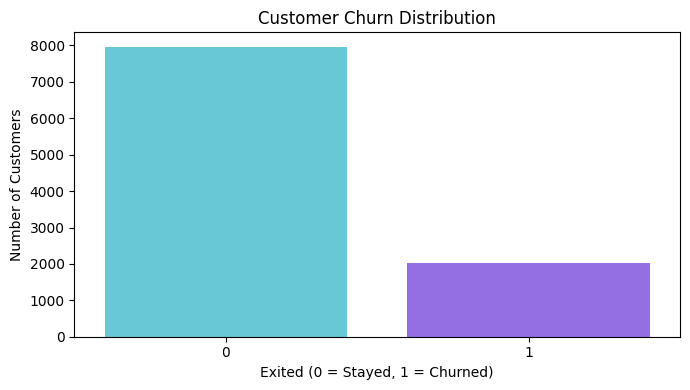

In [13]:
plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="Exited",
    hue="Exited",
    palette=["#57D5E8", "#8B5CF6"],
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Exited (0 = Stayed, 1 = Churned)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

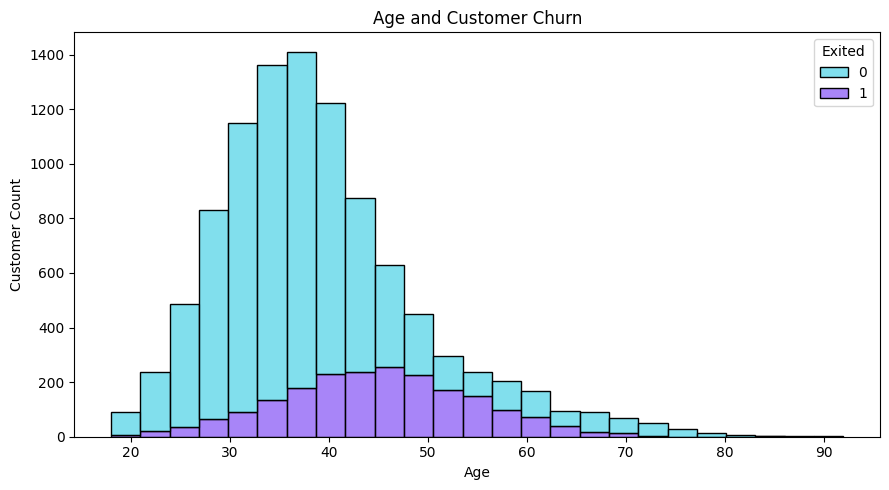

In [14]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Age",
    hue="Exited",
    multiple="stack",
    bins=25,
    palette=["#57D5E8", "#8B5CF6"]
)

plt.title("Age and Customer Churn")
plt.xlabel("Age")
plt.ylabel("Customer Count")

plt.tight_layout()
plt.show()

In [15]:
geography_churn = (
    df.groupby("Geography", observed=True)["Exited"]
      .agg(["count", "mean"])
      .reset_index()
)

geography_churn["ChurnRatePercent"] = (
    geography_churn["mean"] * 100
)

display(geography_churn)

,Geography,count,mean,ChurnRatePercent
0,France,5014,0.161548,16.154767
1,Germany,2509,0.324432,32.443204
2,Spain,2477,0.166734,16.673395


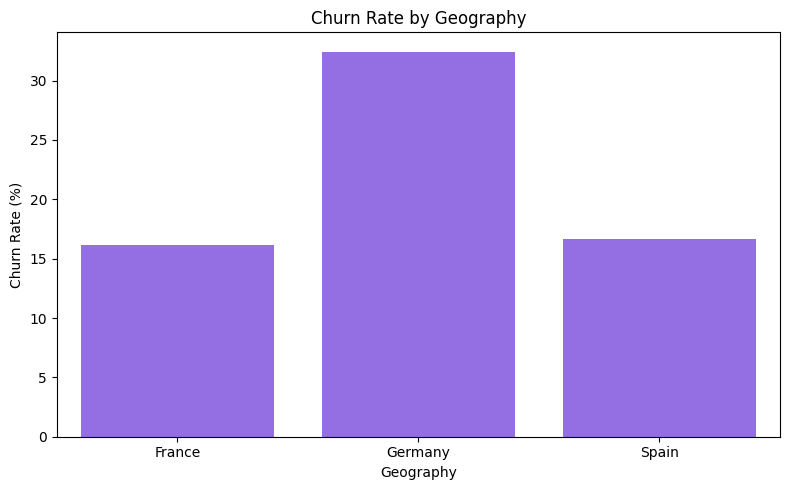

In [16]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=geography_churn,
    x="Geography",
    y="ChurnRatePercent",
    color="#8B5CF6"
)

plt.title("Churn Rate by Geography")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Geography")

plt.tight_layout()
plt.show()

In [17]:
products_churn = (
    df.groupby("NumOfProducts", observed=True)["Exited"]
      .agg(["count", "mean"])
      .reset_index()
)

products_churn["ChurnRatePercent"] = (
    products_churn["mean"] * 100
)

display(products_churn)

,NumOfProducts,count,mean,ChurnRatePercent
0,1,5084,0.277144,27.714398
1,2,4590,0.075817,7.581699
2,3,266,0.827068,82.706767
3,4,60,1.000000,100.000000


In [18]:
membership_churn = (
    df.groupby("IsActiveMember", observed=True)["Exited"]
      .mean()
      .mul(100)
      .rename("ChurnRatePercent")
      .reset_index()
)

display(membership_churn)

,IsActiveMember,ChurnRatePercent
0,0,26.850897
1,1,14.269074


In [19]:
target_column = "Exited"

columns_to_drop = [
    "Exited",
    "RowNumber",
    "CustomerId",
    "Surname"
]

X = df.drop(
    columns=[
        column for column in columns_to_drop
        if column in df.columns
    ]
)

y = df[target_column].astype("int32")

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Feature shape: (10000, 10)
Target shape: (10000,)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,France,Female,42,2,0.00,1,1,1,101348.88
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58
2,502,France,Female,42,8,159660.80,3,1,0,113931.57
3,699,France,Female,39,1,0.00,2,0,0,93826.63
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10


In [20]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    random_state=42,
    stratify=y_train_full
)

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

Training records: 6400
Validation records: 1600
Testing records: 2000


In [21]:
print("Training churn rate:", y_train.mean())
print("Validation churn rate:", y_val.mean())
print("Testing churn rate:", y_test.mean())

Training churn rate: 0.20375
Validation churn rate: 0.20375
Testing churn rate: 0.2035


In [22]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Categorical features: ['Geography', 'Gender']


In [23]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ],
    remainder="drop"
)

In [24]:
X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)

X_test_processed = preprocessor.transform(X_test)

X_train_processed = np.asarray(
    X_train_processed,
    dtype=np.float32
)

X_val_processed = np.asarray(
    X_val_processed,
    dtype=np.float32
)

X_test_processed = np.asarray(
    X_test_processed,
    dtype=np.float32
)

print("Training matrix:", X_train_processed.shape)
print("Validation matrix:", X_val_processed.shape)
print("Testing matrix:", X_test_processed.shape)

Training matrix: (6400, 13)
Validation matrix: (1600, 13)
Testing matrix: (2000, 13)


In [25]:
tf.keras.utils.set_random_seed(42)

model = Sequential(
    [
        Input(shape=(X_train_processed.shape[1],)),

        Dense(
            64,
            activation="relu",
            kernel_regularizer=l2(0.001)
        ),

        Dropout(0.30),

        Dense(
            32,
            activation="relu",
            kernel_regularizer=l2(0.001)
        ),

        Dropout(0.20),

        Dense(
            1,
            activation="sigmoid"
        )
    ]
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,009 (11.75 KB)

 Trainable params: 3,009 (11.75 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
checkpoint_path = ARTIFACT_DIR / "best_ann_model.keras"

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

checkpoint = ModelCheckpoint(
    filepath=str(checkpoint_path),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [27]:
history = model.fit(
    X_train_processed,
    y_train.to_numpy(),
    validation_data=(
        X_val_processed,
        y_val.to_numpy()
    ),
    epochs=100,
    batch_size=32,
    callbacks=[
        early_stopping,
        reduce_lr,
        checkpoint
    ],
    verbose=1
)

Epoch 1/100


200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7498 - auc: 0.5993 - loss: 0.6037 - precision: 0.3048 - recall: 0.1359
Epoch 1: val_loss improved from inf to 0.47827, saving model to /Users/utsav/Desktop/customer-churn-intelligence-v2 2/artifacts/best_ann_model.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - accuracy: 0.7500 - auc: 0.5997 - loss: 0.6034 - precision: 0.3052 - recall: 0.1356 - val_accuracy: 0.8119 - val_auc: 0.7704 - val_loss: 0.4783 - val_precision: 0.8205 - val_recall: 0.0982 - learning_rate: 0.0010
Epoch 2/100
197/200 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8226 - auc: 0.7624 - loss: 0.4841 - precision: 0.7251 - recall: 0.2350
Epoch 2: val_loss improved from 0.47827 to 0.44776, saving model to /Users/utsav/Desktop/customer-churn-intelligence-v2 2/artifacts/best_ann_model.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.8226 - auc: 0.7626 - loss: 0.4838 - precision: 0.7244 - recall: 0.2354 - val_accuracy: 0.8344 - val_auc: 0.7974 - val_l

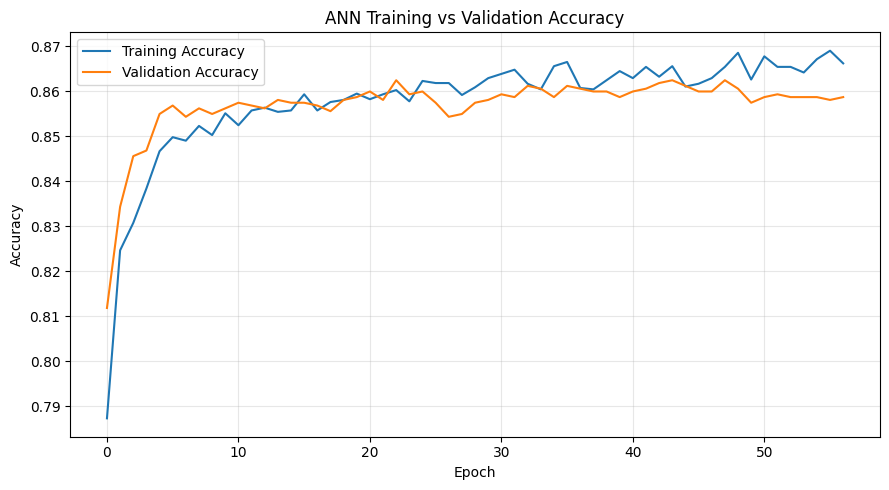

In [28]:
plt.figure(figsize=(9, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("ANN Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

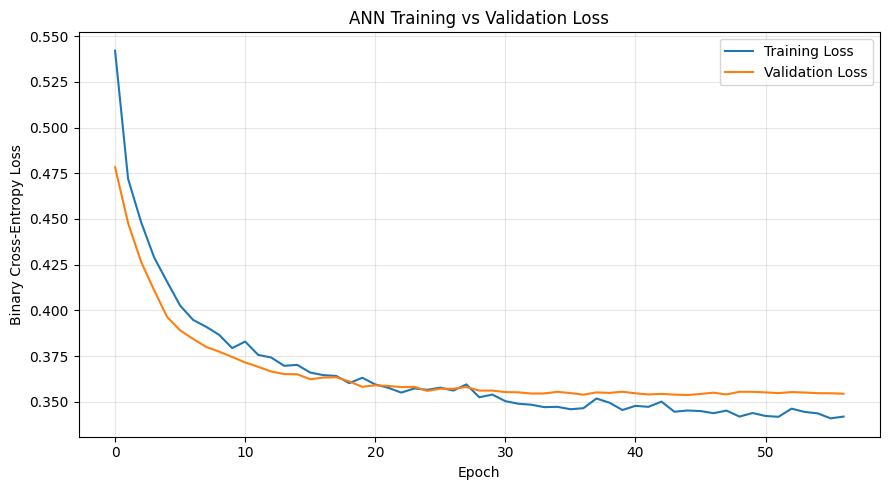

In [29]:
plt.figure(figsize=(9, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("ANN Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [30]:
test_probabilities = model.predict(
    X_test_processed,
    verbose=0
).ravel()

test_predictions = (
    test_probabilities >= 0.5
).astype(int)

print("First 10 churn probabilities:")
print(test_probabilities[:10])

print("\nFirst 10 predicted classes:")
print(test_predictions[:10])

First 10 churn probabilities:
[0.01928029 0.05783491 0.04287007 0.0543071  0.12226272 0.21915507
 0.03026551 0.15887837 0.7111696  0.05107378]

First 10 predicted classes:
[0 0 0 0 0 0 0 0 1 0]


In [31]:
metrics = {
    "accuracy": accuracy_score(
        y_test,
        test_predictions
    ),

    "precision": precision_score(
        y_test,
        test_predictions,
        zero_division=0
    ),

    "recall": recall_score(
        y_test,
        test_predictions,
        zero_division=0
    ),

    "f1_score": f1_score(
        y_test,
        test_predictions,
        zero_division=0
    ),

    "roc_auc": roc_auc_score(
        y_test,
        test_probabilities
    ),

    "average_precision": average_precision_score(
        y_test,
        test_probabilities
    )
}

display(
    pd.DataFrame(
        metrics.items(),
        columns=["Metric", "Value"]
    )
)

,Metric,Value
0,accuracy,0.870000
1,precision,0.802469
2,recall,0.479115
3,f1_score,0.600000
4,roc_auc,0.869086
5,average_precision,0.718967


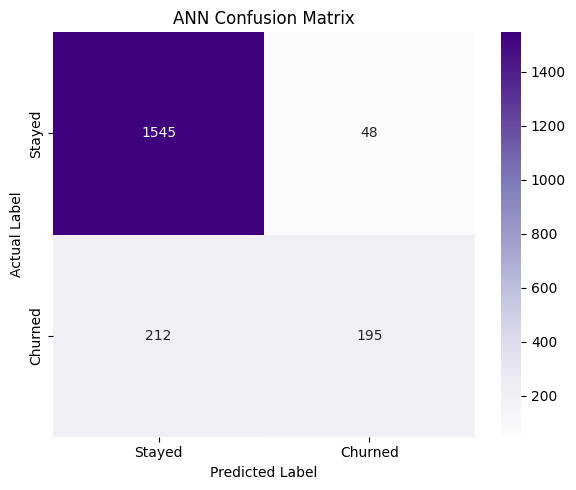

In [32]:
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)

plt.title("ANN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [33]:
baseline = LogisticRegression(
    max_iter=2000,
    class_weight=None,
    random_state=42
)

baseline.fit(
    X_train_processed,
    y_train
)

baseline_probabilities = baseline.predict_proba(
    X_test_processed
)[:, 1]

baseline_predictions = (
    baseline_probabilities >= 0.5
).astype(int)

In [34]:
baseline_metrics = {
    "accuracy": accuracy_score(
        y_test,
        baseline_predictions
    ),

    "precision": precision_score(
        y_test,
        baseline_predictions,
        zero_division=0
    ),

    "recall": recall_score(
        y_test,
        baseline_predictions,
        zero_division=0
    ),

    "f1_score": f1_score(
        y_test,
        baseline_predictions,
        zero_division=0
    ),

    "roc_auc": roc_auc_score(
        y_test,
        baseline_probabilities
    )
}

comparison = pd.DataFrame(
    {
        "ANN": metrics,
        "Logistic Regression": baseline_metrics
    }
)

display(comparison)

,ANN,Logistic Regression
accuracy,0.870000,0.809500
precision,0.802469,0.600000
recall,0.479115,0.191646
f1_score,0.600000,0.290503
roc_auc,0.869086,0.775165
average_precision,0.718967,NaN


In [35]:
model_path = ARTIFACT_DIR / "ann_model.keras"

model.save(model_path)

print("ANN model saved to:", model_path)

ANN model saved to: /Users/utsav/Desktop/customer-churn-intelligence-v2 2/artifacts/ann_model.keras


In [36]:
preprocessor_path = ARTIFACT_DIR / "preprocessor.joblib"

joblib.dump(
    preprocessor,
    preprocessor_path
)

print("Preprocessor saved to:", preprocessor_path)

Preprocessor saved to: /Users/utsav/Desktop/customer-churn-intelligence-v2 2/artifacts/preprocessor.joblib


In [37]:
feature_names = preprocessor.get_feature_names_out().tolist()

metadata = {
    "target_column": "Exited",
    "raw_feature_columns": X_train.columns.tolist(),
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "processed_feature_names": feature_names,
    "decision_threshold": 0.5,
    "risk_thresholds": {
        "low_max": 0.30,
        "medium_max": 0.60
    },
    "random_seed": 42,
    "model_type": "TensorFlow/Keras ANN"
}

with open(
    ARTIFACT_DIR / "metadata.json",
    "w"
) as file:
    json.dump(metadata, file, indent=4)

with open(
    ARTIFACT_DIR / "metrics.json",
    "w"
) as file:
    json.dump(
        {
            key: float(value)
            for key, value in metrics.items()
        },
        file,
        indent=4
    )

with open(
    ARTIFACT_DIR / "training_history.json",
    "w"
) as file:
    json.dump(
        {
            key: [float(v) for v in values]
            for key, values in history.history.items()
        },
        file,
        indent=4
    )

print("Model artifacts saved successfully.")

Model artifacts saved successfully.


In [38]:
loaded_model = tf.keras.models.load_model(
    ARTIFACT_DIR / "ann_model.keras"
)

loaded_preprocessor = joblib.load(
    ARTIFACT_DIR / "preprocessor.joblib"
)

print("Model and preprocessor loaded successfully.")

Model and preprocessor loaded successfully.


In [39]:
sample_customer = pd.DataFrame(
    [
        {
            "CreditScore": 650,
            "Geography": "France",
            "Gender": "Female",
            "Age": 40,
            "Tenure": 5,
            "Balance": 75000.0,
            "NumOfProducts": 2,
            "HasCrCard": 1,
            "IsActiveMember": 1,
            "EstimatedSalary": 80000.0
        }
    ]
)

sample_customer = sample_customer[
    X_train.columns
]

display(sample_customer)

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,650,France,Female,40,5,75000.0,2,1,1,80000.0


In [40]:
processed_customer = loaded_preprocessor.transform(
    sample_customer
)

processed_customer = np.asarray(
    processed_customer,
    dtype=np.float32
)

churn_probability = float(
    loaded_model.predict(
        processed_customer,
        verbose=0
    )[0, 0]
)

retention_probability = 1 - churn_probability

decision_threshold = 0.5

predicted_class = int(
    churn_probability >= decision_threshold
)

if churn_probability < 0.30:
    risk_category = "Low Risk"
elif churn_probability < 0.60:
    risk_category = "Medium Risk"
else:
    risk_category = "High Risk"

print("Predicted class:", predicted_class)
print(f"Churn probability: {churn_probability:.2%}")
print(f"Retention probability: {retention_probability:.2%}")
print("Risk category:", risk_category)

Predicted class: 0
Churn probability: 6.66%
Retention probability: 93.34%
Risk category: Low Risk
